<a href="https://www.kaggle.com/code/fareedhassan/diabetes-predictions?scriptVersionId=368309146" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Explainable Diabetes Risk Prediction
Pima Indians dataset · logistic regression vs random forest · SHAP explanations.

**Setup:** Adding the 'Pima Indians Diabetes Database' dataset (or upload `diabetes_pima_real.csv` from the data pack).

In [1]:
import glob, numpy as np, pandas as pd, matplotlib.pyplot as plt, shap
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report, ConfusionMatrixDisplay, precision_recall_curve
from sklearn.calibration import CalibrationDisplay
SEED = 42
import os
cands = glob.glob('/kaggle/input/**/*.csv', recursive=True) + glob.glob('*.csv')
print('CSV files found:', cands)
path = None
for f in cands:
    try:
        cols = [c.lower() for c in pd.read_csv(f, nrows=1).columns]
    except Exception:
        continue
    if 'outcome' in cols and 'glucose' in cols:   
        path = f; break
if path is None:
    raise FileNotFoundError("No Pima CSV found. Click 'Add Input' (right sidebar) and add 'Pima Indians Diabetes Database', or upload diabetes_pima_real.csv as a dataset and add it.")
df = pd.read_csv(path); df.columns = [c.lower() for c in df.columns]
df = df.rename(columns={'diabetespedigreefunction':'diabetes_pedigree','bloodpressure':'blood_pressure','skinthickness':'skin_thickness'})
print(path, df.shape); df.head()

CSV files found: ['/kaggle/input/datasets/fareedhassan/pima-diabetes-practice-data/diabetes_pima_real.csv']
/kaggle/input/datasets/fareedhassan/pima-diabetes-practice-data/diabetes_pima_real.csv (768, 9)


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
df.head(10)        

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


## 1. Clean: impossible zeros are really missing values

In [3]:
zero_as_nan = ['glucose','blood_pressure','skin_thickness','insulin','bmi']
df[zero_as_nan] = df[zero_as_nan].replace(0, np.nan)
print(df.isna().sum()); print(df.outcome.value_counts(normalize=True).round(3))

pregnancies            0
glucose                5
blood_pressure        35
skin_thickness       227
insulin              374
bmi                   11
diabetes_pedigree      0
age                    0
outcome                0
dtype: int64
outcome
0    0.651
1    0.349
Name: proportion, dtype: float64


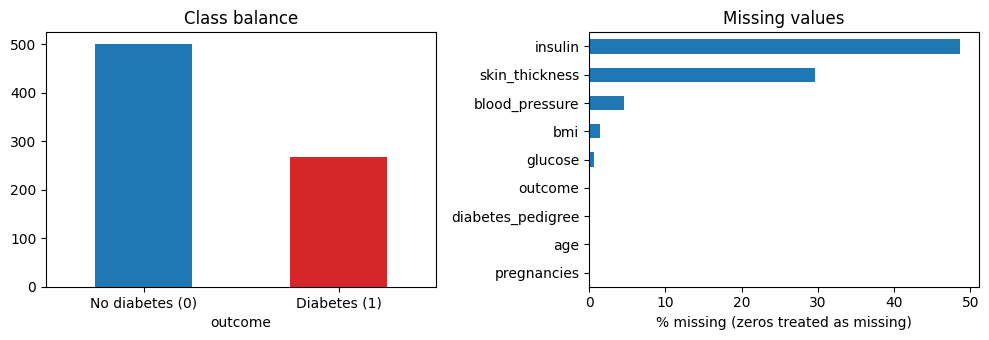

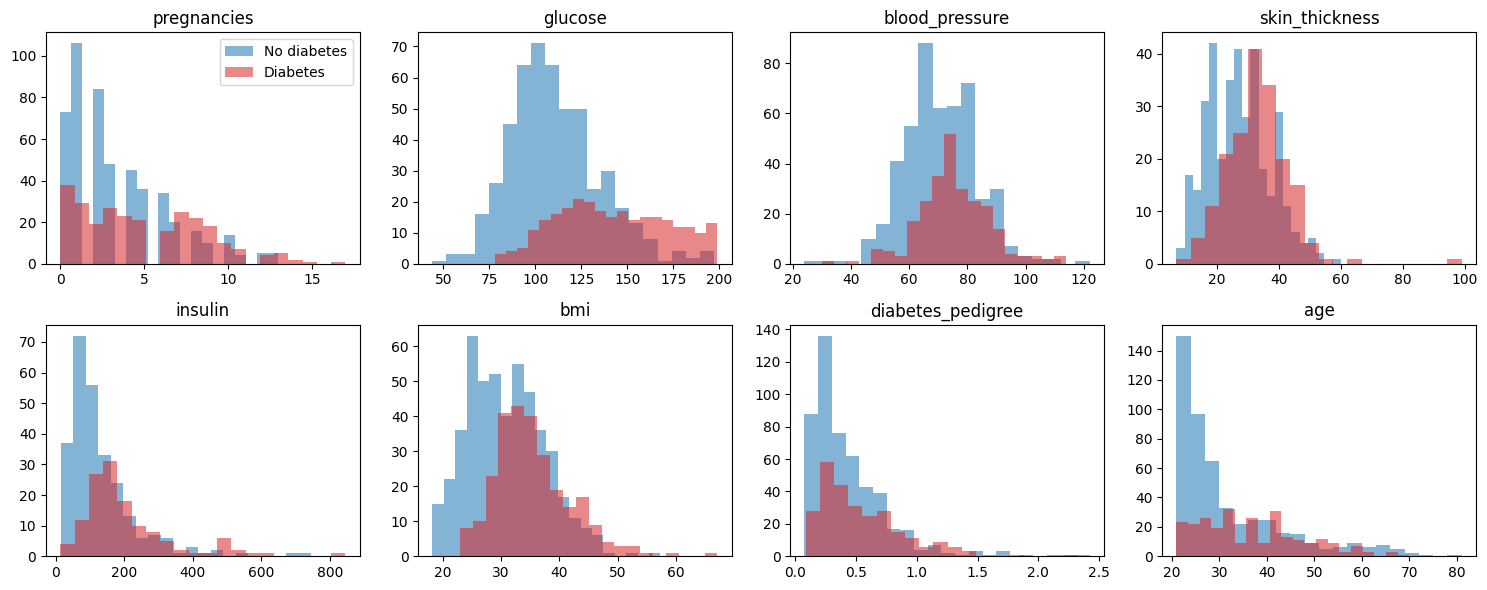

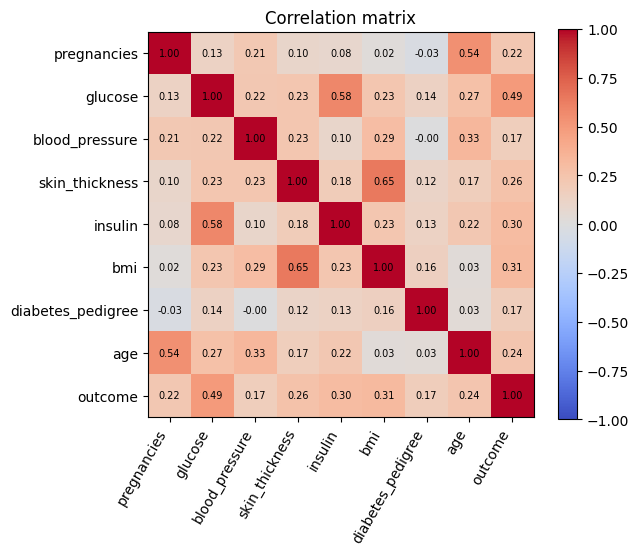

In [4]:
# class balance and missing value
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
df.outcome.value_counts().sort_index().plot.bar(ax=ax[0], color=['C0','C3'], rot=0)
ax[0].set_xticklabels(['No diabetes (0)', 'Diabetes (1)']); ax[0].set_title('Class balance')
(df.isna().mean()*100).sort_values().plot.barh(ax=ax[1])
ax[1].set_xlabel('% missing (zeros treated as missing)'); ax[1].set_title('Missing values')
plt.tight_layout(); plt.show()

# distribution of each feature by outcome
fig, axs = plt.subplots(2, 4, figsize=(15, 6))
for a, c in zip(axs.ravel(), X.columns if 'X' in globals() else df.drop(columns='outcome').columns):
    for v, col in [(0,'C0'), (1,'C3')]:
        a.hist(df.loc[df.outcome==v, c].dropna(), bins=20, alpha=.55, color=col, label=['No diabetes','Diabetes'][v])
    a.set_title(c)
axs[0,0].legend(); plt.tight_layout(); plt.show()

# correlation heatmap
cm = df.corr(); fig, a = plt.subplots(figsize=(6.5, 5.5)); im = a.imshow(cm, cmap='coolwarm', vmin=-1, vmax=1)
a.set_xticks(range(len(cm))); a.set_xticklabels(cm.columns, rotation=60, ha='right'); a.set_yticks(range(len(cm))); a.set_yticklabels(cm.columns)
for i in range(len(cm)):
    for j in range(len(cm)): a.text(j, i, f'{cm.iloc[i,j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im); a.set_title('Correlation matrix'); plt.tight_layout(); plt.show()

In [5]:
df.isna().sum()     # missing values per column
df[df.isna().any(axis=1)].head(10)   # rows that have at least one missing value

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,outcome
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50,1
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31,0
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32,1
5,5,116.0,74.0,NaN,NaN,25.6,0.201,30,0
7,10,115.0,NaN,NaN,NaN,35.3,0.134,29,0
9,8,125.0,96.0,NaN,NaN,NaN,0.232,54,1
10,4,110.0,92.0,NaN,NaN,37.6,0.191,30,0
11,10,168.0,74.0,NaN,NaN,38.0,0.537,34,1
12,10,139.0,80.0,NaN,NaN,27.1,1.441,57,0
15,7,100.0,NaN,NaN,NaN,30.0,0.484,32,1


## 2. Split. Imputation lives inside the pipeline, so no leakage.

In [6]:
X, y = df.drop(columns='outcome'), df.outcome
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
models = {
 'logreg': Pipeline([('imp',SimpleImputer(strategy='median')),('sc',StandardScaler()),('m',LogisticRegression(class_weight='balanced',max_iter=1000))]),
 'rf': Pipeline([('imp',SimpleImputer(strategy='median')),('m',RandomForestClassifier(n_estimators=400,min_samples_leaf=5,class_weight='balanced',random_state=SEED))]),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
for n,m in models.items():
    s = cross_val_score(m, Xtr, ytr, cv=cv, scoring='roc_auc'); print(f'{n}: CV AUC {s.mean():.3f} +/- {s.std():.3f}')

logreg: CV AUC 0.844 +/- 0.016
rf: CV AUC 0.836 +/- 0.021


In [7]:
Xtr.head()   # training features
Xte.head()   # test features
ytr.head()   # training labels

353    0
711    0
373    0
46     0
682    0
Name: outcome, dtype: int64

In [8]:
df.to_csv('diabetes_clean.csv', index=False)

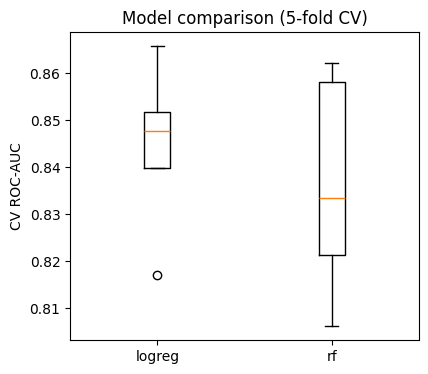

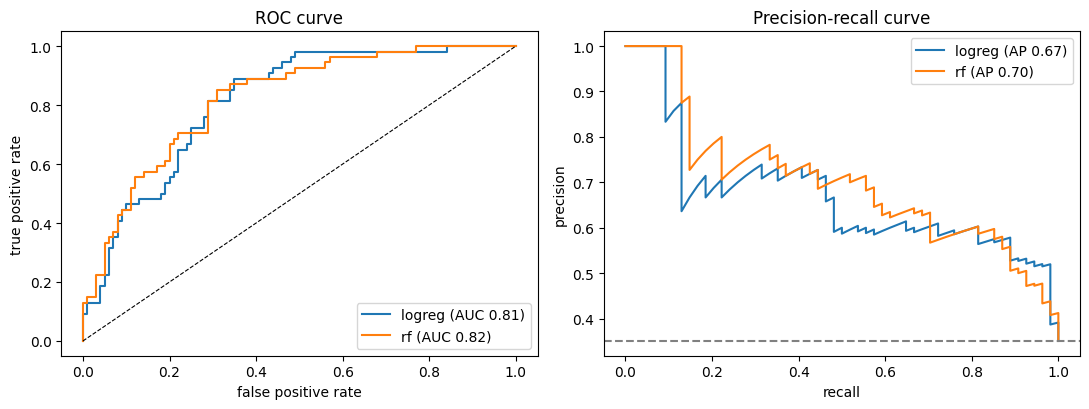

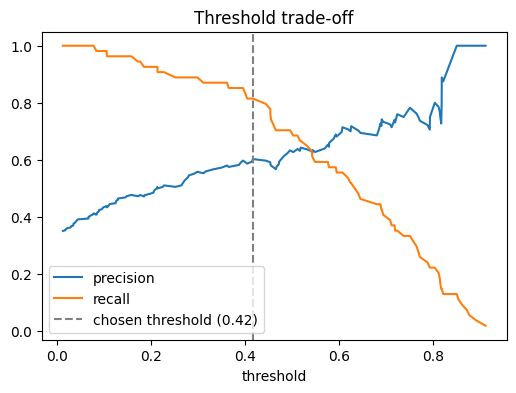

In [9]:
# CV comparison of the two models
sc = {n: cross_val_score(m, Xtr, ytr, cv=cv, scoring='roc_auc') for n, m in models.items()}
plt.figure(figsize=(4.5, 4)); plt.boxplot(list(sc.values()), tick_labels=list(sc))
plt.ylabel('CV ROC-AUC'); plt.title('Model comparison (5-fold CV)'); plt.show()

# ROC and precision-recall curves, both models, on the test set
from sklearn.metrics import roc_curve, average_precision_score
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for n, m in models.items():
    pp = m.fit(Xtr, ytr).predict_proba(Xte)[:, 1]
    f, t, _ = roc_curve(yte, pp); ax[0].plot(f, t, label=f'{n} (AUC {roc_auc_score(yte, pp):.2f})')
    pr_, rc_, _ = precision_recall_curve(yte, pp); ax[1].plot(rc_, pr_, label=f'{n} (AP {average_precision_score(yte, pp):.2f})')
ax[0].plot([0,1], [0,1], 'k--', lw=.8); ax[0].set_xlabel('false positive rate'); ax[0].set_ylabel('true positive rate'); ax[0].set_title('ROC curve'); ax[0].legend()
ax[1].axhline(yte.mean(), color='gray', ls='--'); ax[1].set_xlabel('recall'); ax[1].set_ylabel('precision'); ax[1].set_title('Precision-recall curve'); ax[1].legend()
plt.tight_layout(); plt.show()

# threshold trade-off for the random forest (self-contained)
best = models['rf'].fit(Xtr, ytr)
p = best.predict_proba(Xte)[:, 1]
pr, rc, th = precision_recall_curve(yte, p)
thr = th[np.where(rc[:-1] >= .80)[0].max()]      # threshold giving about 80% recall, same rule as your earlier cell

plt.figure(figsize=(6, 4))
plt.plot(th, pr[:-1], label='precision'); plt.plot(th, rc[:-1], label='recall')
plt.axvline(thr, color='gray', ls='--', label=f'chosen threshold ({thr:.2f})')
plt.xlabel('threshold'); plt.legend(); plt.title('Threshold trade-off'); plt.show()

## 3. Evaluate on the held-out test set

Test AUC: 0.82
Threshold for ~80% recall: 0.417
              precision    recall  f1-score   support

           0       0.88      0.71      0.78       100
           1       0.60      0.81      0.69        54

    accuracy                           0.75       154
   macro avg       0.74      0.76      0.74       154
weighted avg       0.78      0.75      0.75       154



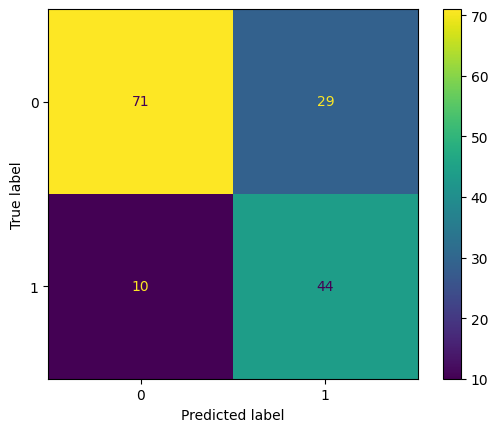

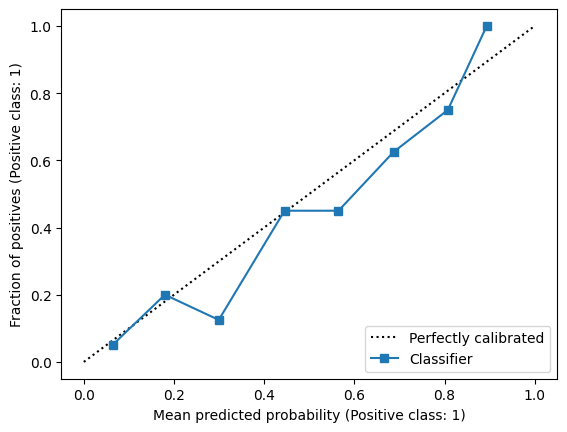

In [10]:
best = models['rf'].fit(Xtr, ytr)          # swap to 'logreg' if it scores better above
p = best.predict_proba(Xte)[:,1]
print('Test AUC:', round(roc_auc_score(yte,p),3))
# choose threshold for recall >= 0.80 (missed cases cost more than false alarms)
pr, rc, th = precision_recall_curve(yte, p)
thr = th[np.where(rc[:-1] >= .80)[0].max()]
print('Threshold for ~80% recall:', round(thr,3))
print(classification_report(yte, (p>=thr).astype(int)))
ConfusionMatrixDisplay.from_predictions(yte, (p>=thr).astype(int)); plt.show()
CalibrationDisplay.from_predictions(yte, p, n_bins=8); plt.show()

## 4. Explain with SHAP

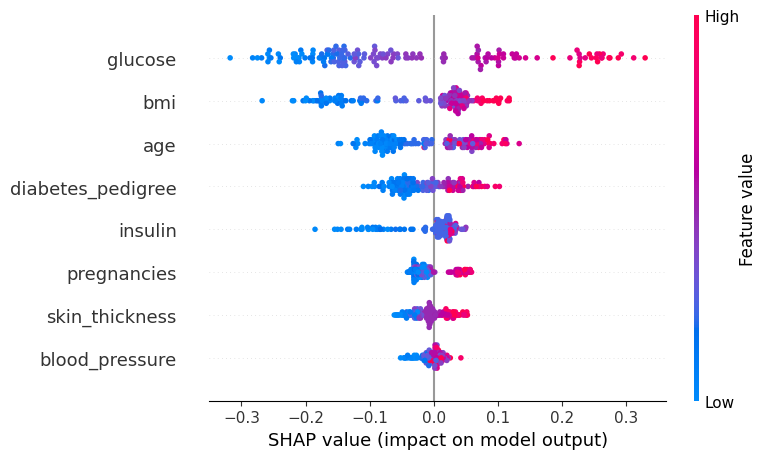

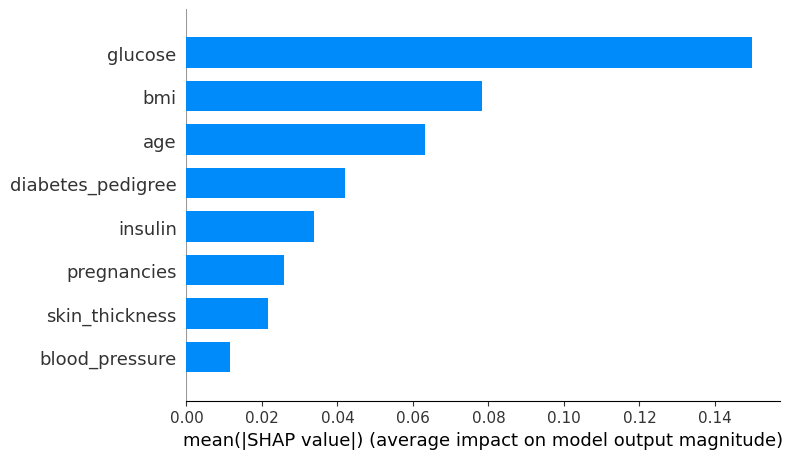

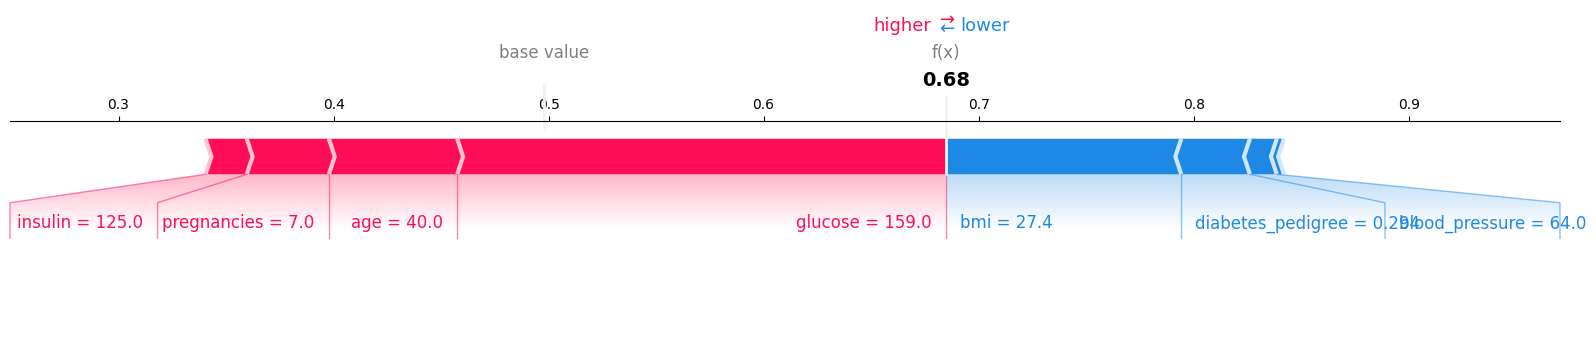

In [11]:
rf = best.named_steps['m']
Xte_imp = pd.DataFrame(best.named_steps['imp'].transform(Xte), columns=X.columns)
sv = shap.TreeExplainer(rf).shap_values(Xte_imp)
sv = sv[1] if isinstance(sv, list) else (sv[:,:,1] if sv.ndim==3 else sv)
shap.summary_plot(sv, Xte_imp)                         # global
shap.summary_plot(sv, Xte_imp, plot_type='bar')
i = 0
shap.force_plot(shap.TreeExplainer(rf).expected_value[1] if np.ndim(shap.TreeExplainer(rf).expected_value) else shap.TreeExplainer(rf).expected_value,
                sv[i], Xte_imp.iloc[i], matplotlib=True)  # one patient

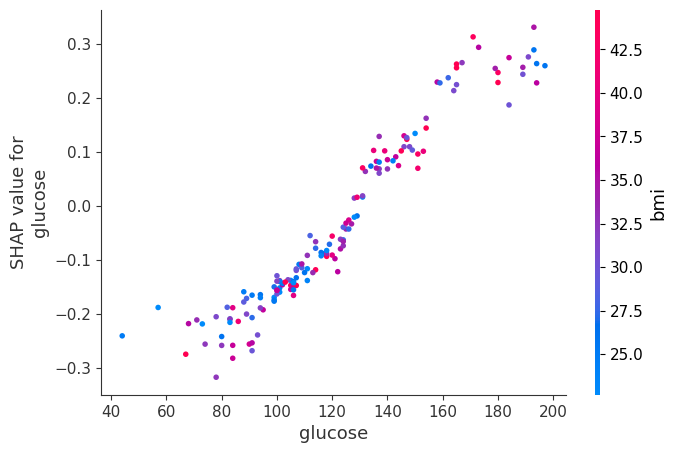

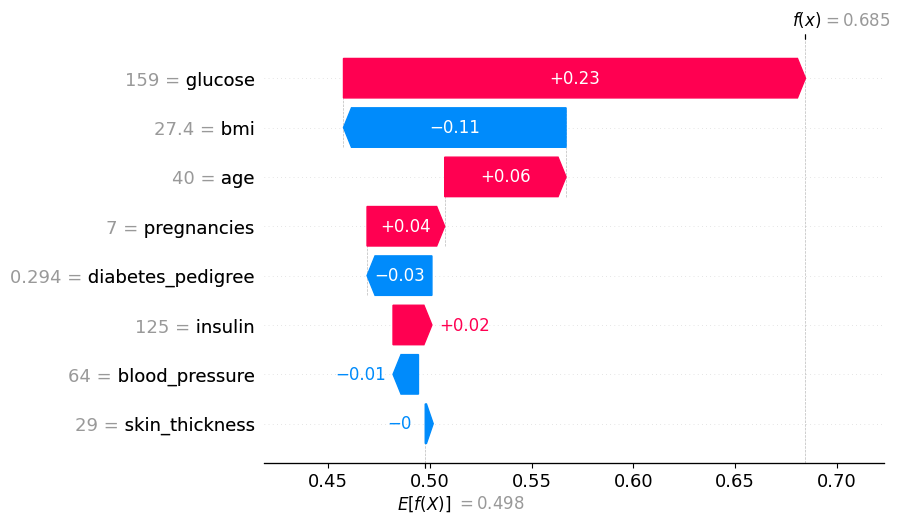

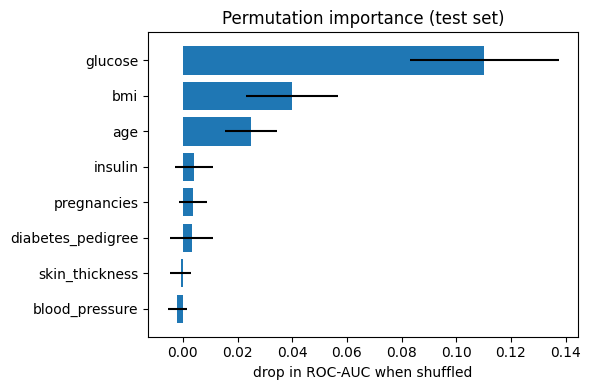

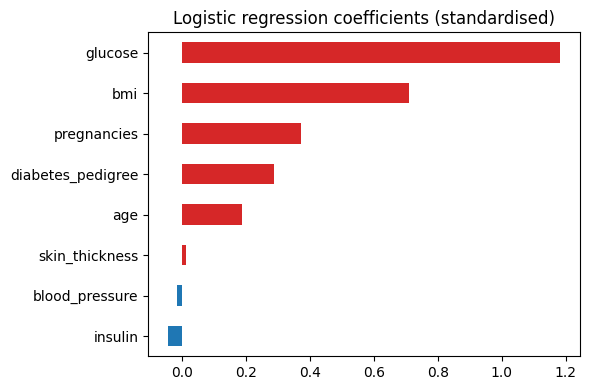

In [12]:
# SHAP dependence: how glucose changes risk, coloured by BMI
shap.dependence_plot('glucose', sv, Xte_imp, interaction_index='bmi')

# SHAP waterfall for one patient (easier to read than the force plot)
ex = shap.TreeExplainer(rf); ev = ex.expected_value; ev = ev[1] if np.ndim(ev) else ev
shap.plots.waterfall(shap.Explanation(values=sv[0], base_values=ev, data=Xte_imp.iloc[0].values, feature_names=list(X.columns)))

# permutation importance on the test set
from sklearn.inspection import permutation_importance
r = permutation_importance(best, Xte, yte, scoring='roc_auc', n_repeats=20, random_state=SEED)
o = np.argsort(r.importances_mean); plt.figure(figsize=(6, 4))
plt.barh(X.columns[o], r.importances_mean[o], xerr=r.importances_std[o])
plt.xlabel('drop in ROC-AUC when shuffled'); plt.title('Permutation importance (test set)'); plt.tight_layout(); plt.show()

# logistic regression coefficients (this model scored slightly better in CV)
lr = models['logreg'].fit(Xtr, ytr); co = pd.Series(lr.named_steps['m'].coef_[0], index=X.columns).sort_values()
plt.figure(figsize=(6, 4)); co.plot.barh(color=np.where(co > 0, 'C3', 'C0')); plt.title('Logistic regression coefficients (standardised)'); plt.tight_layout(); plt.show()